In [1]:
!ls 

1.Pipeline_Sentiment_Analysis.ipynb
2.Pipeline-Text-Generation.ipynb
3.Pipeline-Masked-Language-Modeling.ipynb
4.Pipeline_NER.ipynb
5.Pipeline-Summarization.ipynb
6.Pipeline-Translation.ipynb
Note.md
Resources
data
images
machine_learning_examples


In [2]:
! ls data

AirlineTweets.csv ner_test.pkl      robert_frost.txt
bbc_text_cls.csv  ner_train.pkl     spa-eng


In [3]:
!ls data/spa-eng/

_about.txt spa.txt


In [4]:
!head data/spa-eng/spa.txt

Go.	Ve.
Go.	Vete.
Go.	Vaya.
Go.	Váyase.
Hi.	Hola.
Run!	¡Corre!
Run.	Corred.
Who?	¿Quién?
Fire!	¡Fuego!
Fire!	¡Incendio!


In [5]:
#compile eng-spa translations
eng2spa = {}
for line in open('data/spa-eng/spa.txt'):
    line = line.rstrip()
    eng, spa = line.split("\t")
    if eng not in eng2spa:
        eng2spa[eng] = []
    eng2spa[eng].append(spa)

In [6]:
eng2spa

{'Go.': ['Ve.', 'Vete.', 'Vaya.', 'Váyase.'],
 'Hi.': ['Hola.'],
 'Run!': ['¡Corre!'],
 'Run.': ['Corred.'],
 'Who?': ['¿Quién?'],
 'Fire!': ['¡Fuego!', '¡Incendio!', '¡Disparad!'],
 'Help!': ['¡Ayuda!', '¡Socorro! ¡Auxilio!', '¡Auxilio!'],
 'Jump!': ['¡Salta!'],
 'Jump.': ['Salte.'],
 'Stop!': ['¡Parad!', '¡Para!', '¡Pare!'],
 'Wait!': ['¡Espera!'],
 'Wait.': ['Esperen.'],
 'Go on.': ['Continúa.', 'Continúe.'],
 'Hello!': ['Hola.'],
 'I ran.': ['Corrí.', 'Corría.'],
 'I try.': ['Lo intento.'],
 'I won!': ['¡He ganado!'],
 'Oh no!': ['¡Oh, no!'],
 'Relax.': ['Tomátelo con soda.'],
 'Smile.': ['Sonríe.'],
 'Attack!': ['¡Al ataque!', '¡Atacad!'],
 'Get up.': ['Levanta.'],
 'Go now.': ['Ve ahora mismo.'],
 'Got it!': ['¡Lo tengo!'],
 'Got it?': ['¿Lo pillas?', '¿Entendiste?'],
 'He ran.': ['Él corrió.'],
 'Hop in.': ['Métete adentro.'],
 'Hug me.': ['Abrázame.'],
 'I fell.': ['Me caí.'],
 'I know.': ['Yo lo sé.'],
 'I left.': ['Salí.'],
 'I lied.': ['Mentí.'],
 'I lost.': ['Perdí.'],
 'I 

In [7]:
from nltk.translate.bleu_score import sentence_bleu,SmoothingFunction

In [8]:
from nltk.tokenize import RegexpTokenizer
tokenizer = RegexpTokenizer(r'\w+')

In [9]:
tokenizer.tokenize('¿Qué me cuentas ?'.lower())

['qué', 'me', 'cuentas']

In [10]:
tokens = tokenizer.tokenize('¿Qué me cuentas ?'.lower())
sentence_bleu([tokens],tokens)

/Users/ankit/Workspace/Projects/ankit-github/AI-ML-DS/.venv/lib/python3.12/site-packages/nltk/translate/bleu_score.py:577: UserWarning: 
The hypothesis contains 0 counts of 4-gram overlaps.
Therefore the BLEU score evaluates to 0, independently of
how many N-gram overlaps of lower order it contains.
Consider using lower n-gram order or use SmoothingFunction()
  warnings.warn(_msg)


1.2213386697554703e-77

In [11]:
sentence_bleu([['hi']],['hi'])

/Users/ankit/Workspace/Projects/ankit-github/AI-ML-DS/.venv/lib/python3.12/site-packages/nltk/translate/bleu_score.py:577: UserWarning: 
The hypothesis contains 0 counts of 2-gram overlaps.
Therefore the BLEU score evaluates to 0, independently of
how many N-gram overlaps of lower order it contains.
Consider using lower n-gram order or use SmoothingFunction()
  warnings.warn(_msg)
/Users/ankit/Workspace/Projects/ankit-github/AI-ML-DS/.venv/lib/python3.12/site-packages/nltk/translate/bleu_score.py:577: UserWarning: 
The hypothesis contains 0 counts of 3-gram overlaps.
Therefore the BLEU score evaluates to 0, independently of
how many N-gram overlaps of lower order it contains.
Consider using lower n-gram order or use SmoothingFunction()
  warnings.warn(_msg)


1.821831989445342e-231

In [12]:
smoother = SmoothingFunction()
sentence_bleu(['hi'],'hi',smoothing_function=smoother.method4)

0.2213885886251307

In [13]:
sentence_bleu(['hi there'.split()], 'hi there'.split())

1.491668146240062e-154

In [14]:
sentence_bleu(['hi there friend'.split()], 'hi there friend'.split())

1.2213386697554703e-77

In [15]:
sentence_bleu([[1,2,3,4]],[1,2,3,4])

1.0

In [16]:
eng2spa_tokens = {}
for eng, spa_list in eng2spa.items():
    spa_list_tokens = []
    for text in spa_list:
        tokens = tokenizer.tokenize(text.lower())
        spa_list_tokens.append(tokens)
    eng2spa_tokens[eng] = spa_list_tokens

In [17]:
from transformers import pipeline
translator = pipeline("translation", model="Helsinki-NLP/opus-mt-en-es",device='mps', framework='pt')

/Users/ankit/Workspace/Projects/ankit-github/AI-ML-DS/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
/Users/ankit/Workspace/Projects/ankit-github/AI-ML-DS/.venv/lib/python3.12/site-packages/transformers/models/marian/tokenization_marian.py:175: UserWarning: Recommended: pip install sacremoses.
  warnings.warn("Recommended: pip install sacremoses.")
Device set to use mps


In [18]:
translator('I like eggs and ham')

[{'translation_text': 'Me gustan los huevos y el jamón.'}]

In [19]:
eng_phrases = list(eng2spa.keys())
len(eng_phrases)

102904

In [20]:
eng_phrases_subset = eng_phrases[20_000:21_000]

In [21]:
# 27 mins for 10k phrases on GPU
translations = translator(eng_phrases_subset)

In [22]:
translations[0]

{'translation_text': 'Tom está en el jardín.'}

In [23]:
import math
from nltk.translate.bleu_score import modified_precision, brevity_penalty, closest_ref_length

def bleu_old(references, hypothesis, weights=(0.25, 0.25, 0.25, 0.25)):
    """Sentence BLEU as in older NLTK versions (as used in the course).

    Newer NLTK returns 0 whenever any n-gram order has no overlap (e.g. any
    sentence shorter than 4 tokens). Older versions just skipped those orders.
    """
    p_n = [modified_precision(references, hypothesis, i) for i in range(1, len(weights) + 1)]
    if p_n[0].numerator == 0:
        return 0
    hyp_len = len(hypothesis)
    bp = brevity_penalty(closest_ref_length(references, hyp_len), hyp_len)
    s = sum(w * math.log(p) for w, p in zip(weights, p_n) if p > 0)
    return bp * math.exp(s)

scores = []
for eng,pred in zip(eng_phrases_subset, translations):
    matches = eng2spa_tokens[eng]

    # tokenize translation
    spa_pred = tokenizer.tokenize(pred['translation_text'].lower())

    score = bleu_old(matches, spa_pred)
    scores.append(score)


(array([ 21.,   0.,   0.,   0.,   0.,   1.,   0.,   0.,   0.,   0.,   1.,
          0.,   0.,   1.,   0.,   3.,   1.,   0.,   2.,   7.,   2.,  10.,
          2.,  10.,   7.,  15.,   3.,  42.,  20.,   6.,  28.,  27.,  17.,
         18.,   0., 108.,   4.,  72.,   7.,  19.,   2.,   0.,  41.,   0.,
          1.,  14.,   4.,   1.,   0., 483.]),
 array([0.  , 0.02, 0.04, 0.06, 0.08, 0.1 , 0.12, 0.14, 0.16, 0.18, 0.2 ,
        0.22, 0.24, 0.26, 0.28, 0.3 , 0.32, 0.34, 0.36, 0.38, 0.4 , 0.42,
        0.44, 0.46, 0.48, 0.5 , 0.52, 0.54, 0.56, 0.58, 0.6 , 0.62, 0.64,
        0.66, 0.68, 0.7 , 0.72, 0.74, 0.76, 0.78, 0.8 , 0.82, 0.84, 0.86,
        0.88, 0.9 , 0.92, 0.94, 0.96, 0.98, 1.  ]),
 <BarContainer object of 50 artists>)

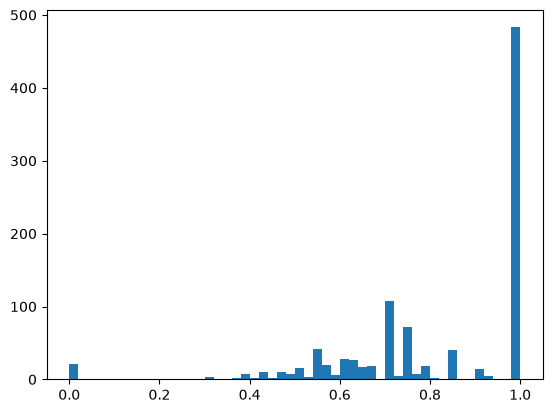

In [24]:
import matplotlib.pyplot as plt
plt.hist(scores, bins=50)

In [25]:
import numpy as np
np.mean(scores)

np.float64(0.8157024707405215)

In [26]:
np.random.seed(1)

def print_random_translation():
    i = np.random.choice(len(eng_phrases_subset))
    eng = eng_phrases_subset[i]
    print("EN: ", eng)

    translation = translations[i]['translation_text']
    print("ES Translation: ", translation)

    matches = eng2spa[eng]
    print("Matches: ", matches)

In [27]:
print_random_translation()

EN:  Tom isn't that young.
ES Translation:  Tom no es tan joven.
Matches:  ['Tom no es tan joven.']


In [28]:
print_random_translation()

EN:  Tom's Mary's brother.
ES Translation:  Tom es el hermano de Mary.
Matches:  ['Tom es el hermano de Mary.']


In [29]:
print_random_translation()

EN:  Can you describe them?
ES Translation:  ¿Puede describirlos?
Matches:  ['¿Podrías describirles?', '¿Podrías describirlos?']
